In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from data_loader import load_dataset, load_raw_data
from preprocessing import split_features, build_preprocessor
from config import RANDOM_STATE, TEST_SIZE, MODEL_DIR

In [2]:
raw_df = load_raw_data()

print("Raw shape:", raw_df.shape)

print("\nRaw Springfield_bars description:")
print(raw_df["Springfield_bars"].describe())

Raw shape: (39997, 66)

Raw Springfield_bars description:
count    3.999700e+04
mean     1.230616e+03
std      1.252276e+04
min      0.000000e+00
25%      1.013000e+03
50%      1.017000e+03
75%      1.021000e+03
max      1.008371e+06
Name: Springfield_bars, dtype: float64


In [3]:
print("Values < 900:")
print((raw_df["Springfield_bars"] < 900).sum())

print("\nValues == 0:")
print((raw_df["Springfield_bars"] == 0).sum())

print("\nLarge corrupted values (>10000):")
print((raw_df["Springfield_bars"] > 10000).sum())

Values < 900:
2

Values == 0:
1

Large corrupted values (>10000):
33


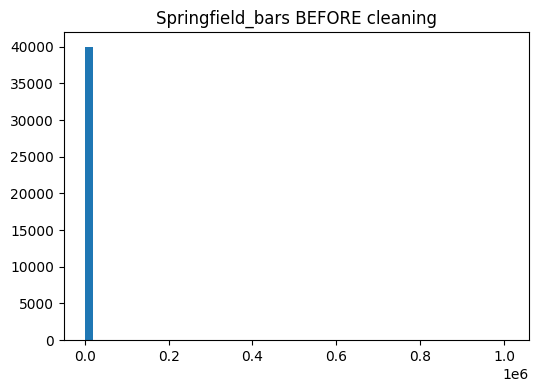

In [4]:
plt.figure(figsize=(6,4))
plt.hist(raw_df["Springfield_bars"], bins=50)
plt.title("Springfield_bars BEFORE cleaning")
plt.show()

In [5]:
X, y, cleaned_df = load_dataset()

print("Cleaned X shape:", X.shape)
print("Cleaned y shape:", y.shape)

Removed constant columns: ['New New York_snow', 'Springfield_snow']
Cleaned X shape: (39997, 63)
Cleaned y shape: (39997,)


In [6]:
print("BEFORE cleaning (raw):")
print(raw_df["Springfield_bars"].describe())

print("\nAFTER cleaning:")
print(cleaned_df["Springfield_bars"].describe())

BEFORE cleaning (raw):
count    3.999700e+04
mean     1.230616e+03
std      1.252276e+04
min      0.000000e+00
25%      1.013000e+03
50%      1.017000e+03
75%      1.021000e+03
max      1.008371e+06
Name: Springfield_bars, dtype: float64

AFTER cleaning:
count    39993.000000
mean      1016.606613
std          7.568702
min        918.000000
25%       1013.000000
50%       1017.000000
75%       1021.000000
max       1039.000000
Name: Springfield_bars, dtype: float64


In [7]:
raw_nan = raw_df["Springfield_bars"].isna().sum()
clean_nan = cleaned_df["Springfield_bars"].isna().sum()

print("NaNs in RAW:", raw_nan)
print("NaNs AFTER cleaning:", clean_nan)
print("New NaNs created:", clean_nan - raw_nan)

NaNs in RAW: 0
NaNs AFTER cleaning: 4
New NaNs created: 4


In [8]:
print("Values < 900:")
print((cleaned_df["Springfield_bars"] < 900).sum())

print("\nValues == 0:")
print((cleaned_df["Springfield_bars"] == 0).sum())

print("\nLarge corrupted values (>10000):")
print((cleaned_df["Springfield_bars"] > 10000).sum())

Values < 900:
0

Values == 0:
0

Large corrupted values (>10000):
0


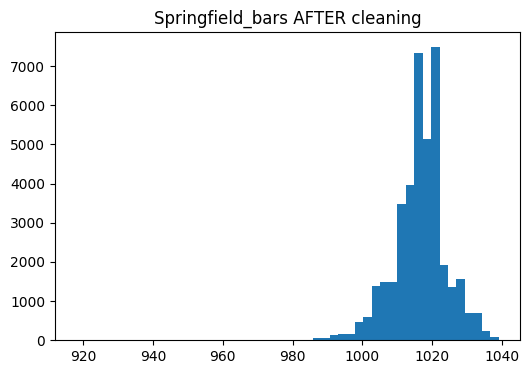

In [9]:
plt.figure(figsize=(6,4))
plt.hist(cleaned_df["Springfield_bars"].dropna(), bins=50)
plt.title("Springfield_bars AFTER cleaning")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Valid shape:", X_valid.shape)

Train shape: (31997, 63)
Valid shape: (8000, 63)


In [11]:
numeric_features, categorical_features = split_features(X_train)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 53
Categorical features: 10


In [12]:
preprocessor = build_preprocessor(
    numeric_features,
    categorical_features
)

In [13]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_valid_prepared = preprocessor.transform(X_valid)

print("Train transformed shape:", X_train_prepared.shape)
print("Valid transformed shape:", X_valid_prepared.shape)

Train transformed shape: (31997, 250)
Valid transformed shape: (8000, 250)


In [14]:
import numpy as np

if hasattr(X_train_prepared, "toarray"):
    nan_count = np.isnan(X_train_prepared.toarray()).sum()
else:
    nan_count = np.isnan(X_train_prepared).sum()

print("NaNs in final training matrix:", nan_count)

NaNs in final training matrix: 0


In [15]:
joblib.dump(
    preprocessor,
    MODEL_DIR / "preprocessor.pkl"
)

['C:\\Users\\BAB AL SAFA\\Desktop\\Projets\\powerpredict-ml-project\\models\\preprocessor.pkl']